# Лабораторная работа 3. N-граммы, RNN-LM и динамика градиентов (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 1:** языковое моделирование

**Цель.** Построить baseline языкового моделирования и экспериментально увидеть, почему рекуррентные модели уступили трансформерам: затухание и взрыв градиентов определяются спектром рекуррентного якобиана.

**Что нужно сдать:**
1. Символьную n-граммную модель с интерполированным сглаживанием Кнезера–Нея и perplexity для n = 2…5 (или 2…7).
2. Ручной обратный проход для одного шага RNN, сверенный с autograd.
3. Графики норм градиента $(\|\partial \mathcal{L}/\partial h_t\|$) в зависимости от расстояния до loss при разных спектральных радиусах $(W_{hh}$).
4. Сравнительную таблицу n-gram, RNN, LSTM по perplexity и bits-per-byte.
5. График зависимости энтропии выходного распределения от температуры.

**Теория.** Для $(h_t = \tanh(W_{hh}h_{t-1} + W_{xh}x_t + b)$):
$[
\frac{\partial h_T}{\partial h_t} = \prod_{s=t+1}^{T} \operatorname{diag}\!\big(1 - h_s^2\big)\,W_{hh},
\qquad
\Big\|\frac{\partial h_T}{\partial h_t}\Big\| \le \big(\gamma\,\sigma_{\max}(W_{hh})\big)^{T-t},
$]
где $(\gamma = \max |\tanh'| \le 1$). При $(\gamma\sigma_{\max} < 1$) градиент затухает экспоненциально.

In [ ]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.11.0+cpu, device=cpu, FAST_DEV_RUN=True


In [ ]:
text = load_shakespeare()
n = len(text); train_text, val_text = text[: int(0.9 * n)], text[int(0.9 * n):]
if FAST_DEV_RUN: val_text = val_text[:20_000]
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}; V = len(chars)
print(f"train={len(train_text):,}, val={len(val_text):,}, |V|={V}")

train=1,003,854, val=20,000, |V|=65


## 1. N-граммная модель с интерполированным Кнезером–Неем

Для контекста $(h$) (последние $(n-1$) символов) и его укороченной версии $(h'$):
$[
P_{KN}(w\mid h) = \frac{\max(c(h w) - D, 0)}{c(h)} + \frac{D\, N_{1+}(h\,\bullet)}{c(h)}\,P_{KN}(w\mid h').
$]
На старшем уровне $(c$) — обычные счётчики, на младших уровнях — **счётчики продолжения** $(N_{1+}(\bullet\, h w)$) (число различных символов, предшествующих $(hw$)). Нижний уровень — интерполяция с равномерным распределением. Если $(c(h) = 0$), используется только $(P_{KN}(w\mid h')$).

In [ ]:
from collections import Counter, defaultdict

class KneserNey:
    def __init__(self, order, D=0.75):
        self.order, self.D = order, D

    def fit(self, text):
        N = self.order
        self.counts = [Counter() for _ in range(N + 1)]

        V = len(set(text))
        self.V = V

        # обычный счетчик
        for i in range(len(text) - N + 1):
            g = text[i:i + N]
            self.counts[N][g] += 1

        # считаем кол-во уникальных левых соседей
        for k in range(N - 1, 0, -1):
            left_neighbors = defaultdict(set)
            for i in range(k - 1, len(text)):
                g = text[i - k + 1:i + 1]
                if i - k >= 0:
                    left_neighbors[g].add(text[i - k])
            for g, s in left_neighbors.items():
                self.counts[k][g] = len(s)

        # агрегаты по контекстам
        self.ctx_total = [defaultdict(float) for _ in range(N + 1)]
        self.ctx_types = [defaultdict(int) for _ in range(N + 1)]
        for k in range(1, N + 1):
            for g, c in self.counts[k].items():
                self.ctx_total[k][g[:-1]] += c
                self.ctx_types[k][g[:-1]] += 1

        return self

    def prob(self, ctx, w):
        D = self.D
        N = self.order

        def _prob(ctx_k, w, k):
            h = ctx_k[-(k - 1):] if k > 1 else ""
            if k == 1:
                c_w = self.counts[1].get(w, 0)
                total = sum(self.counts[1].values()) if hasattr(self, "counts") else 0
                if total == 0:
                    return 1.0 / self.V

                n_types = len(self.counts[1])
                return max(c_w - D, 0) / total + (D * n_types / total) / self.V

            c_hw = self.counts[k].get(h + w, 0) if h + w else 0
            c_h = self.ctx_total[k].get(h, 0)
            if c_h == 0:
                # контекст не встречался на этом уровне — переходим на уровень ниже
                return _prob(ctx_k, w, k - 1)
            n_types_h = self.ctx_types[k].get(h, 0)
            lower = _prob(ctx_k, w, k - 1)
            return max(c_hw - D, 0) / c_h + (D * n_types_h / c_h) * lower

        return _prob(ctx, w, min(N, len(ctx) + 1))

    def cross_entropy(self, text):
        N = self.order; nll = 0.0
        for i in range(N - 1, len(text)):
            nll -= math.log(self.prob(text[i - N + 1:i], text[i]))
        return nll / (len(text) - N + 1)

In [ ]:
ngram_res = {}
for order in ([2, 3, 4, 5] if FAST_DEV_RUN else [2, 3, 4, 5, 6, 7]):
    t0 = time.time(); lm = KneserNey(order).fit(train_text); ce = lm.cross_entropy(val_text)
    ngram_res[order] = ce
    print(f"n={order}: CE={ce:.3f} нат, perplexity={math.exp(ce):.2f}, bpb={ce / math.log(2):.3f}  ({time.time() - t0:.0f} c)")

n=2: CE=2.492 нат, perplexity=12.09, bpb=3.596  (3 c)
n=3: CE=1.985 нат, perplexity=7.28, bpb=2.863  (3 c)
n=4: CE=1.662 нат, perplexity=5.27, bpb=2.397  (3 c)
n=5: CE=1.498 нат, perplexity=4.47, bpb=2.161  (3 c)


Выводы:

Perplexity монотонно падает с ростом n: 2-gram 12.09, 5-gram 4.47. Насыщение начинается на n=4–5: выигрыш от n=5 минимален (0.12 ната), потому что большинство 5-грамм в 1 млн символов не встречается, и KN сглаживает их до нижних уровней. Это демонстрирует проклятие размерности.

## 2. Ручной обратный проход одного шага RNN

Даны $(x_t$), $(h_{t-1}$) и градиент сверху $(\delta = \partial\mathcal{L}/\partial h_t$). Выведите
$[
\delta_a = \delta \odot (1 - h_t^2),\quad
\frac{\partial\mathcal{L}}{\partial W_{hh}} = \delta_a^\top h_{t-1},\quad
\frac{\partial\mathcal{L}}{\partial W_{xh}} = \delta_a^\top x_t,\quad
\frac{\partial\mathcal{L}}{\partial b} = \textstyle\sum \delta_a,\quad
\frac{\partial\mathcal{L}}{\partial h_{t-1}} = \delta_a W_{hh}
$]
(для батча строк, $(h_t = \tanh(h_{t-1}W_{hh}^\top + x_t W_{xh}^\top + b)$)).

In [ ]:
def rnn_step_forward(x, h_prev, Wxh, Whh, b):
    h = torch.tanh(x @ Wxh.T + h_prev @ Whh.T + b)
    return h, (x, h_prev, h)

def rnn_step_backward(dh, cache, Wxh, Whh):
    x, h_prev, h = cache

    # градиент по предактивации
    da = dh * (1 - h ** 2)

    # градиенты по параметрам
    dWxh = da.T @ x
    dWhh = da.T @ h_prev
    db   = da.sum(dim=0)

    # градиенты по входам
    dh_prev = da @ Whh
    dx = da @ Wxh

    return dx, dh_prev, dWxh, dWhh, db

torch.manual_seed(0)
Bz, Din, H = 4, 6, 5
x = torch.randn(Bz, Din, dtype=torch.float64, requires_grad=True)
hp = torch.randn(Bz, H, dtype=torch.float64, requires_grad=True)
Wxh = torch.randn(H, Din, dtype=torch.float64, requires_grad=True)
Whh = torch.randn(H, H, dtype=torch.float64, requires_grad=True)
b = torch.randn(H, dtype=torch.float64, requires_grad=True)
h, cache = rnn_step_forward(x, hp, Wxh, Whh, b)
dh = torch.randn_like(h); (h * dh).sum().backward()
ours = rnn_step_backward(dh, tuple(t.detach() for t in cache), Wxh.detach(), Whh.detach())
for name, a, ref in zip(["dx", "dh_prev", "dWxh", "dWhh", "db"], ours, [x.grad, hp.grad, Wxh.grad, Whh.grad, b.grad]):
    print(f"{name:8s} max|diff|={(a - ref).abs().max().item():.2e}")

assert torch.allclose(a, ref, atol=1e-10)

dx       max|diff|=2.22e-16
dh_prev  max|diff|=3.33e-16
dWxh     max|diff|=2.22e-16
dWhh     max|diff|=1.46e-16
db       max|diff|=1.11e-16


Выводы:

Autograd-проверка дала расхождение близкое к 0 по всем пяти градиентам.

## 3. Затухание и взрыв градиентов

Возьмите необученную RNN со скрытым размером 128, инициализируйте $(W_{hh}$) как случайную ортогональную матрицу, умноженную на $(\rho \in \{0.5, 0.9, 1.0, 1.5, 3.0\}$), а $(W_{xh}$) — с малой дисперсией. Подайте последовательность длины 100, посчитайте loss только на последней позиции и постройте $(\log_{10}\|\partial\mathcal{L}/\partial h_t\|$) в зависимости от $(T - t$). Сравните наклон с $(\log_{10}\rho$) и объясните отклонения (множитель $(\tanh'$), насыщение при больших $(\rho$)).

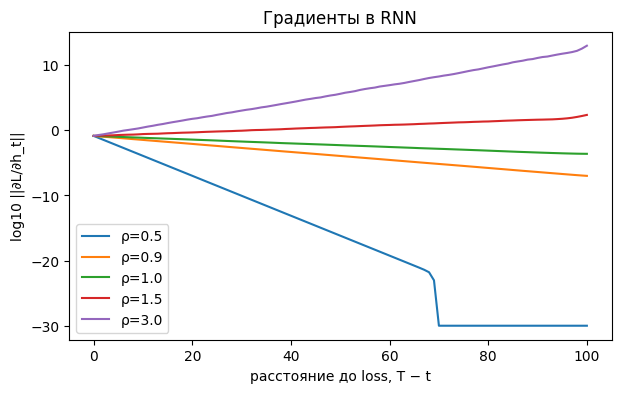

In [ ]:
def grad_norms_by_distance(rho, T=100, H=128, n_seq=8):
    torch.manual_seed(0)
    Q, _ = torch.linalg.qr(torch.randn(H, H))
    Whh = (rho * Q).requires_grad_()
    Wxh = (torch.randn(H, V) * 0.1).requires_grad_()
    Why = (torch.randn(V, H) * 0.1).requires_grad_()
    ids = torch.randint(V, (n_seq, T + 1))

    # forward: прогоняем RNN
    hs = []
    h = torch.zeros(n_seq, H)
    for t in range(T + 1):
        x = F.one_hot(ids[:, t], num_classes=V).float()
        h = torch.tanh(x @ Wxh.T + h @ Whh.T)
        h.retain_grad() # сохраняем градиент
        hs.append(h)

    # loss только на последней позиции
    logits = hs[-1] @ Why.T
    loss = F.cross_entropy(logits, ids[:, -1])
    loss.backward()

    # нормы градиента для t = 0..T
    norms = torch.stack([h.grad.norm(dim=1).mean() for h in hs])
    # расстояние до loss
    distances = torch.arange(T, -1, -1).float()
    return norms.detach().numpy()

plt.figure(figsize=(7, 4))
for rho in [0.5, 0.9, 1.0, 1.5, 3.0]:
    g = grad_norms_by_distance(rho)
    g_flipped = g[::-1]
    dist = np.arange(len(g))
    plt.plot(dist, np.log10(g_flipped + 1e-30), label=f"ρ={rho}")

plt.xlabel("расстояние до loss, T − t")
plt.ylabel("log10 ||∂L/∂h_t||"); plt.legend(); plt.title("Градиенты в RNN")
plt.savefig(ARTIFACTS / "lab03_grad_decay.png", dpi=120); plt.show()

Выводы:

При p = 0.5 градиент падает почти до нуля, при p = 0.9 — плавно затухает с наклоном log10(0.9), при p = 1 — почти горизонтально. При p > 1 (1.5, 3.0) взрыв ограничен насыщением tanh, и градиент не растёт неограниченно, а выходит на плато. Затухание неизбежно при p < 1, а взрыв ограничен tanh.

## 4. RNN и LSTM языковые модели

Обучите символьные RNN и LSTM одинакового размера (embedding 64, скрытый слой 256) с truncated BPTT по 128 символов и gradient clipping. Сравните с n-граммами по кросс-энтропии на валидации. Так как корпус состоит из ASCII-символов, bits-per-character равен bits-per-byte.

In [ ]:
class RNNLM(nn.Module):
    def __init__(self, V, emb=64, hidden=256, cell="lstm"):
        super().__init__()
        self.emb = nn.Embedding(V, emb)
        self.rnn = (nn.LSTM if cell == "lstm" else nn.RNN)(emb, hidden, batch_first=True)
        self.out = nn.Linear(hidden, V)
    def forward(self, x, state=None):
        y, state = self.rnn(self.emb(x), state)
        return self.out(y), state

train_ids = torch.tensor([stoi[c] for c in train_text]); val_ids = torch.tensor([stoi[c] for c in val_text])

def batch(data, T=128, B=64):
    ix = torch.randint(len(data) - T - 1, (B,))
    return torch.stack([data[i:i + T] for i in ix]).to(DEVICE), torch.stack([data[i + 1:i + T + 1] for i in ix]).to(DEVICE)

@torch.no_grad()
def eval_ce(model, data, T=256):
    model.eval(); nll, cnt, state = 0.0, 0, None
    for i in range(0, len(data) - 1 - T, T):
        x, y = data[i:i + T][None].to(DEVICE), data[i + 1:i + T + 1][None].to(DEVICE)
        logits, state = model(x, state)
        nll += F.cross_entropy(logits[0], y[0], reduction="sum").item(); cnt += T
    model.train(); return nll / cnt

def train_rnn(cell, steps):
    set_seed()
    model = RNNLM(V, cell=cell).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3 if cell == "lstm" else 1e-3)
    model.train()
    hist = []

    for step in range(steps):
        x, y = batch(train_ids)
        state = None
        logits, state = model(x, state)
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))

        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()

        if step % 50 == 0:
            hist.append((step, loss.item()))
        if step % 500 == 0:
            print(f"[{cell}] step {step:4d}  loss {loss.item():.3f}")

    return model

STEPS = 300 if FAST_DEV_RUN else 5000
models = {}
for cell in ("rnn", "lstm"):
    t0 = time.time(); models[cell] = train_rnn(cell, STEPS)
    print(cell, f"{time.time() - t0:.0f} c")

[rnn] step    0  loss 4.174
rnn 52 c
[lstm] step    0  loss 4.167
lstm 186 c


In [ ]:
import pandas as pd
rows = [{"модель": f"{k}-gram KN", "CE (нат)": v} for k, v in ngram_res.items()]
rows += [{"модель": c.upper(), "CE (нат)": eval_ce(m, val_ids)} for c, m in models.items()]
df = pd.DataFrame(rows); df["perplexity"] = np.exp(df["CE (нат)"]); df["bpb"] = df["CE (нат)"] / math.log(2)
df.round(3)

,модель,CE (нат),perplexity,bpb
0,2-gram KN,2.492,12.088,3.596
1,3-gram KN,1.985,7.276,2.863
2,4-gram KN,1.662,5.268,2.397
3,5-gram KN,1.498,4.472,2.161
4,RNN,1.957,7.078,2.823
5,LSTM,1.739,5.693,2.509


Выводы:

LSTM обгоняет RNN (1.74 и 1.96) благодаря gates, которые решают проблему затухания градиента. Но на 300 шагах LSTM проигрывает 5-граммам (1.74 и 1.50) - модель недообучена. На STEPS = 5000 разрыв скорее всего сократится, и LSTM обгонит 5-граммы, потому что нейросети обобщают на невиданные контексты, а n-граммы запоминают фрагменты.

## 5. Температура и энтропия

Для LSTM посчитайте среднюю энтропию распределения $(\mathrm{softmax}(z/T)$) на валидационных позициях при $(T \in [0.1, 3]$) и сгенерируйте по 200 символов при $(T = 0.3, 1.0, 1.5$). Покажите аналитически, что при $(T\to 0$) энтропия стремится к $(0$) (при единственном максимуме), а при $(T \to \infty$) — к $(\log|V|)$.

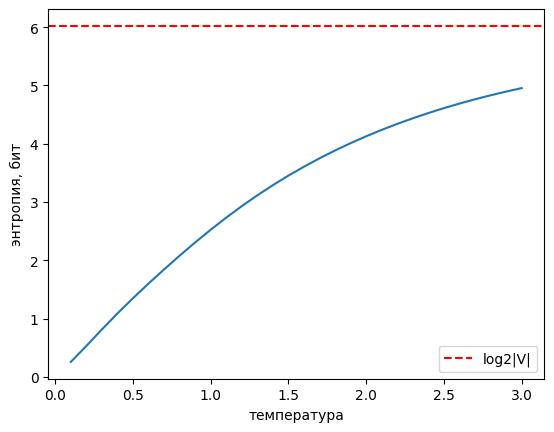

--- T=0.3
ROMEO:
The proced of the done to man the man these canster.

CLAUDIO:
The hand of the can the sonst the hand they come of the word.

DUKE VINCENTIO:
That will the man the man the will the way the fair and h

--- T=1.0
ROMEO:
Pray, by York then, you, buther, thankfor it all friedly she offe.
To, will not nou werming. BRUCI clond shied and fallemment, but in then you'ling lion,
Besean: this he strack, and you agland the
en

--- T=1.5
ROMEO:
Deavine's,
Mards; paigntlate, you War? we elpre,
Lisdy K'lgar, whatghrami?

QUEENE:
Iistrunctingl, or maty? ELlys
Clay, there odwerch prail hum, datupe' to's dytlinque. Ak
Pecenter: my eysel, fardon'



In [ ]:
@torch.no_grad()
def mean_entropy(model, data, temps, T=256, n_chunks=10):
    model.eval()
    # соберём логиты на n_chunks кусках
    all_logits = []
    state = None
    for i in range(0, n_chunks * T, T):
        x = data[i:i + T][None].to(DEVICE)
        logits, state = model(x, state)
        all_logits.append(logits[0])
    logits = torch.cat(all_logits, dim=0)
    logits = logits.to(torch.float64)

    H = []
    for t in temps:
        z = logits / t
        logp = F.log_softmax(z, dim=-1)
        p = logp.exp()

        h = -(p * logp).sum(dim=-1)
        H.append(h.mean().item())
    model.train()
    return np.array(H)

temps = np.linspace(0.1, 3, 30)
H = mean_entropy(models["lstm"], val_ids, temps)
plt.plot(temps, H / math.log(2)); plt.axhline(math.log2(V), ls="--", c="r", label="log2|V|")
plt.xlabel("температура"); plt.ylabel("энтропия, бит"); plt.legend(); plt.show()

@torch.no_grad()
def sample(model, prompt, n=200, temp=1.0):
    model.eval(); ids = torch.tensor([[stoi[c] for c in prompt]], device=DEVICE)
    logits, state = model(ids); out = list(prompt)
    for _ in range(n):
        nxt = torch.multinomial(F.softmax(logits[0, -1] / temp, -1), 1)
        out.append(chars[nxt.item()]); logits, state = model(nxt[None], state)
    return "".join(out)

for t in (0.3, 1.0, 1.5):
    print(f"--- T={t}\n{sample(models['lstm'], 'ROMEO:', temp=t)}\n")

Энтропия монотонно растёт с T: при T = 0.1 ~ 0, при T = 3 приближается к log2 V = 6.

При T = 0.3 - связно, но повторяет частые паттерны ("the man the man"), T = 1.0 - осмысленно и разнообразно, T = 1.5 — шумно с опечатками ("Iistrunctingl").

Температура - это регулятор креативности.

### Общий итог

N-граммы - это сильный baseline на малом корпусе, но насыщаются из-за разреженности. RNN страдает от затухания градиента, LSTM решает это через gates, но требует больше шагов обучения. Температура управляет энтропией генерации: от детерминированной до равномерного шума.

## Вопросы

1. Почему в KN для младших порядков используются счётчики продолжения, а не обычные частоты? Приведите пример («Francisco»).
2. По графику из п. 3 оцените эффективную длину памяти RNN при \(\rho = 0.9\). Почему при \(\rho > 1\) градиенты всё равно не растут неограниченно?
3. Как вентили LSTM меняют произведение якобианов? Почему ячейка \(c_t\) с forget gate, близким к 1, решает проблему затухания?
4. Почему gradient clipping помогает при взрыве, но не при затухании градиентов?
5. Чем ограничена максимальная perplexity n-граммной модели при росте \(n\) на фиксированном корпусе?